1. Import the necessary libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

2. Load the dataset and check Imbalance

In [3]:
# Load the dataset
df = pd.read_csv(r"creditcard.csv")

In [9]:
print("="*50)
print("BASIC INFO")
print("="*50)
print(f"Shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nData Types:\n{df.dtypes}")
print(f"\nFirst 5 rows:")
display(df.head())

BASIC INFO
Shape: (284807, 31)

Columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Data Types:
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

First 5 rows:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [10]:
print("\n" + "="*50)
print("MISSING VALUES")
print("="*50)
print(df.isnull().sum().sum())   

print("\n" + "="*50)
print("CLASS DISTRIBUTION")
print("="*50)
print(df['Class'].value_counts())
print()
print("Percentage:")
print(df['Class'].value_counts(normalize=True) * 100)



MISSING VALUES
0

CLASS DISTRIBUTION
Class
0    284315
1       492
Name: count, dtype: int64

Percentage:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


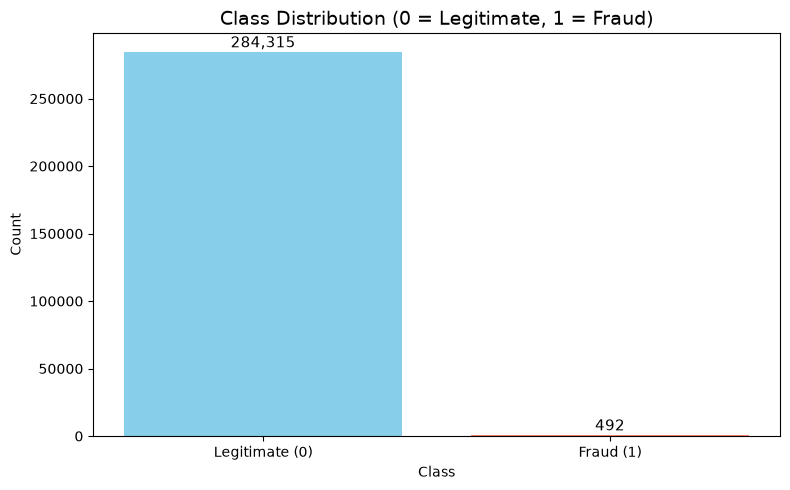

In [13]:
#Visualize the imbalance
counts = df['Class'].value_counts().sort_index()

plt.figure(figsize=(8, 5))
bars = plt.bar(['Legitimate (0)', 'Fraud (1)'], counts.values, color=['skyblue', 'salmon'])

plt.title('Class Distribution (0 = Legitimate, 1 = Fraud)', fontsize=14)
plt.ylabel('Count')
plt.xlabel('Class')

# Add count labels on top of the bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 1000, f'{int(height):,}', 
             ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.show()

3. Train-Test Split

In [14]:
#Train-Test Split
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop('Class', axis=1)
y = df['Class']

# Split the data (80% train, 20% test)
# stratify=y is important so both sets keep the same fraud ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Test set shape:    ", X_test.shape)
print()

print("Fraud distribution in Training set:")
print(y_train.value_counts(normalize=True) * 100)
print()
print("Fraud distribution in Test set:")
print(y_test.value_counts(normalize=True) * 100)

Training set shape: (227845, 30)
Test set shape:     (56962, 30)

Fraud distribution in Training set:
Class
0    99.827075
1     0.172925
Name: proportion, dtype: float64

Fraud distribution in Test set:
Class
0    99.827955
1     0.172045
Name: proportion, dtype: float64


4. Apply Smote

In [16]:
from imblearn.over_sampling import SMOTE

print("Before SMOTE:")
print(y_train.value_counts())
print()

# Create SMOTE object
smote = SMOTE(random_state=42)

# Apply SMOTE only on training data
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("After SMOTE:")
print(y_train_smote.value_counts())
print()
print("New training set shape:", X_train_smote.shape)

Before SMOTE:
Class
0    227451
1       394
Name: count, dtype: int64

After SMOTE:
Class
0    227451
1    227451
Name: count, dtype: int64

New training set shape: (454902, 30)


Train the model
 1. Logistic Regression
 2. Random Forest

In [18]:
#Train Models
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create a pipeline: Scale → Logistic Regression
log_reg = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        max_iter=5000,
        solver='saga',         
        random_state=42
    ))
])

print("Training Logistic Regression (with scaling + max_iter=5000)...")
log_reg.fit(X_train_smote, y_train_smote)

print("Logistic Regression trained successfully!")

# 2. Random Forest
print("Training Random Forest...")
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train_smote, y_train_smote)

print("\nBoth models trained successfully!")

Training Logistic Regression (with scaling + max_iter=5000)...
Logistic Regression trained successfully!
Training Random Forest...

Both models trained successfully!


Evaluate Models (Precision, Recall, ROC-AUC)

In [19]:
#Model Evaluation 

def evaluate_model(model, X_test, y_test, model_name):
    print("="*60)
    print(f"EVALUATION: {model_name}")
    print("="*60)
    
    # Predictions
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]  # probability of fraud
    
    # Classification Report (includes Precision, Recall, F1)
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=['Legitimate', 'Fraud']))
    
    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    print("Confusion Matrix:")
    print(cm)
    print(f"\nTrue Negatives: {cm[0,0]}")
    print(f"False Positives: {cm[0,1]}")
    print(f"False Negatives: {cm[1,0]}")
    print(f"True Positives:  {cm[1,1]}")
    
    # ROC-AUC Score
    roc_auc = roc_auc_score(y_test, y_proba)
    print(f"\nROC-AUC Score: {roc_auc:.4f}")
    
    return y_pred, y_proba, roc_auc

# Evaluate Logistic Regression
y_pred_lr, y_proba_lr, roc_lr = evaluate_model(log_reg, X_test, y_test, "Logistic Regression")

print("\n\n")

# Evaluate Random Forest
y_pred_rf, y_proba_rf, roc_rf = evaluate_model(rf, X_test, y_test, "Random Forest")

EVALUATION: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.99      0.99     56864
       Fraud       0.13      0.90      0.23        98

    accuracy                           0.99     56962
   macro avg       0.57      0.94      0.61     56962
weighted avg       1.00      0.99      0.99     56962

Confusion Matrix:
[[56293   571]
 [   10    88]]

True Negatives: 56293
False Positives: 571
False Negatives: 10
True Positives:  88

ROC-AUC Score: 0.9768



EVALUATION: Random Forest

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.84      0.83      0.83        98

    accuracy                           1.00     56962
   macro avg       0.92      0.91      0.92     56962
weighted avg       1.00      1.00      1.00     56962

Confusion Matrix:
[[56848    16]
 [   17    81]]

True Negatives: 56848
False Pos

Plot ROC curves

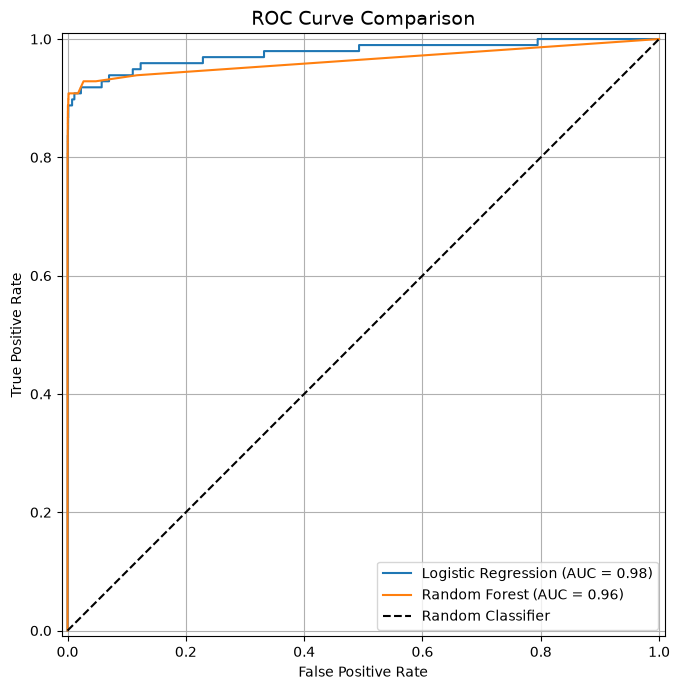

Logistic Regression ROC-AUC: 0.9768
Random Forest ROC-AUC:       0.9644


In [20]:
#ROC Curve Comparison 
from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(10, 7))

# Plot ROC curve for Logistic Regression
RocCurveDisplay.from_estimator(log_reg, X_test, y_test, name='Logistic Regression', ax=plt.gca())

# Plot ROC curve for Random Forest
RocCurveDisplay.from_estimator(rf, X_test, y_test, name='Random Forest', ax=plt.gca())

# Plot random classifier line
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

plt.title('ROC Curve Comparison', fontsize=14)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print(f"Logistic Regression ROC-AUC: {roc_lr:.4f}")
print(f"Random Forest ROC-AUC:       {roc_rf:.4f}")

## Final Model Selected: Logistic Regression

### Why Logistic Regression?
- Highest ROC-AUC score: **0.9768**
- Best Recall on Fraud class: **0.90** (only 10 fraud cases missed)
- Strong overall ability to detect the minority class

### Key Results (Test Set)

| Metric                    | Score      |
|---------------------------|------------|
| Precision (Fraud)         | 0.13       |
| Recall (Fraud)            | 0.90       |
| F1-Score (Fraud)          | 0.23       |
| ROC-AUC                   | 0.9768     |
| False Negatives           | 10         |
| False Positives           | 571        |